In a dilute liquid phase reactor the reaction A + B = C reaches equilibrium . Initial concentration are [A] = 0.5 , [B] =0.5 AND [C] =0 MOL/liquid . If x mol/l of c is formed , kc = x/(0.5-x)^2 , which rearranges to the quadratic equation kcx^2 - (kc=1)x =0.25.kc = 0
write a python program that :
(a) reads kc using input() , prints the data type of the raw input and of the converted value , and shows a clear message (no crash) if the text is not a number or if kc<= 0;
(b) finds a,b,c, the discriminant and both roots;
(c) selectes the physically meaningful root (0<=x<=0.5);
(d) prints equilibrium [A],[B],[C], (3 DECIMALS) and the conversion of the limiting reactant = x/[A] * 100% ;
(e) classifies the conversion using if / elif / else :>= 70% "high" ,>=40% "moderate", otherwise "low".



In [10]:
import math


raw_kc = input("Enter the equilibrium constant Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid Kc: enter a finite number greater than 0.")
    else:
        # Kc * x**2 - (Kc + 1) * x + 0.25 * Kc = 0
        a = kc
        b = -(kc + 1)
        c = 0.25 * kc
        discriminant = b**2 - 4 * a * c

        print(f"a = {a}, b = {b}, c = {c}")
        print("Discriminant:", discriminant)

        if discriminant < 0:
            print("No real roots.")
        else:
            sqrt_discriminant = math.sqrt(discriminant)
            root1 = (-b + sqrt_discriminant) / (2 * a)
            root2 = (-b - sqrt_discriminant) / (2 * a)
            print("Root 1:", root1)
            print("Root 2:", root2)

            if 0 <= root1 <= 0.5:
                x = root1
            elif 0 <= root2 <= 0.5:
                x = root2
            else:
                print("No root satisfies the physical range 0 <= x <= 0.5.")
                x = None

            if x is not None:
                equilibrium_a = 0.5 - x
                equilibrium_b = 0.5 - x
                equilibrium_c = x
                conversion = x / 0.5 * 100

                print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
                print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
                print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
                print(f"Limiting-reactant conversion = {conversion:.3f}%")

                if conversion >= 70:
                    classification = "high"
                elif conversion >= 40:
                    classification = "moderate"
                else:
                    classification = "low"

                print("Conversion classification:", classification)


Raw input type: <class 'str'>
Converted value type: <class 'float'>
a = 0.5, b = -1.5, c = 0.125
Discriminant: 2.0
Root 1: 2.914213562373095
Root 2: 0.08578643762690485
Equilibrium [A] = 0.414 mol/L
Equilibrium [B] = 0.414 mol/L
Equilibrium [C] = 0.086 mol/L
Limiting-reactant conversion = 17.157%
Conversion classification: low


Part A. a pollutant in wastewater is degraded in a batch photoreactor by a first-order reaction , dC/dT = -kC . Use the euler method : C_new + C_old - kC_old.deltaT. Take C0 = 1.0 mol/l , k =0.12 min^-1 ,deltaT =0.5 min.
1. using a for loop , stimulate 5 min and print a table of time (min) , concentration (mol/l) and conversion (%) .
2. using math.exp(), calculate the exact value C0e^(-kt) at 5 min amd print the absolute error of the euler result .
3. using a while loop, repeat the simulation until the conversion reaches 70% or time reaches 100 min . print the time needed and the final concentration.

Part B. storage -tanks lots such as TK0045-LOT19 are stored as text , Write a program that reads a lot code , loops through each character , and prints the number of digits and the sum of the digits . show a message for an empty code and for a code with no digits .

In [9]:
import math

# Part A: Euler simulation for the first 5 minutes.
c0 = 1.0
k = 0.12
dt = 0.5
c = c0
time = 0.0

print("Part A: Euler simulation (0 to 5 min)")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>16}")
print(f"{time:10.1f} {c:24.4f} {(c0 - c) / c0 * 100:16.2f}")

for step in range(int(5 / dt)):
    c_new = c - k * c * dt
    c = c_new
    time += dt
    conversion = (c0 - c) / c0 * 100
    print(f"{time:10.1f} {c:24.4f} {conversion:16.2f}")

euler_concentration = c
exact_concentration = c0 * math.exp(-k * 5)
absolute_error = abs(euler_concentration - exact_concentration)
print(f"\nExact concentration at 5 min: {exact_concentration:.6f} mol/L")
print(f"Absolute error at 5 min: {absolute_error:.6f} mol/L")

# Repeat from the initial concentration until 70% conversion or 100 min.
c = c0
time = 0.0
conversion = 0.0
while conversion < 70 and time < 100:
    c = c - k * c * dt
    time += dt
    conversion = (c0 - c) / c0 * 100

print("\nPart A: 70% conversion stopping condition")
if conversion >= 70:
    print(f"Conversion reached 70% at {time:.1f} min ({conversion:.2f}%).")
else:
    print("The conversion did not reach 70% within 100 min.")
print(f"Final concentration: {c:.6f} mol/L")

# Part B: count and sum the digits in a storage-tank lot code.
lot_code = input("\nEnter a storage-tank lot code: ")
if not lot_code.strip():
    print("The lot code is empty.")
else:
    digit_count = 0
    digit_sum = 0
    for character in lot_code:
        if character.isdecimal():
            digit_count += 1
            digit_sum += int(character)

    print("Number of digits:", digit_count)
    print("Sum of digits:", digit_sum)
    if digit_count == 0:
        print("The lot code contains no digits.")


Part A: Euler simulation (0 to 5 min)
Time (min)    Concentration (mol/L)   Conversion (%)
       0.0                   1.0000             0.00
       0.5                   0.9400             6.00
       1.0                   0.8836            11.64
       1.5                   0.8306            16.94
       2.0                   0.7807            21.93
       2.5                   0.7339            26.61
       3.0                   0.6899            31.01
       3.5                   0.6485            35.15
       4.0                   0.6096            39.04
       4.5                   0.5730            42.70
       5.0                   0.5386            46.14

Exact concentration at 5 min: 0.548812 mol/L
Absolute error at 5 min: 0.010197 mol/L

Part A: 70% conversion stopping condition
Conversion reached 70% at 10.0 min (70.99%).
Final concentration: 0.290106 mol/L
Number of digits: 0
Sum of digits: 0
The lot code contains no digits.


Part A. A plant has n candidate feed components and wants to blend r of them (order does not matter0. Write a recursive function factorial (n) (remember the base case for 0factorial) and a fucntion combination (n,r) =nfactorial/rfactorial*(n-r)factorial that uses it . reject invalid input9negative values,r>n). print the number of possible blends for n =8, r=4, and show the message for n=3 , r=5.

Part B , during a cooling experiment ,temperature readings are taken at times= Fibonacci number *3min . Write an iterative function fib_iter(n) that returns a list of the first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th fibonacci number (F0=0,F1=1) , for n=8 , check that both functions agree and print a table:Reading No. | Fibonacci tag | Time (min).

In [11]:
# Part A: recursive factorial and combinations.
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if not isinstance(r, int) or isinstance(r, bool):
        raise TypeError("r must be an integer.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Part A: Combinations")
print("Number of blends for n=8, r=4:", combination(8, 4))
try:
    combination(3, 5)
except (TypeError, ValueError) as error:
    print(f"Invalid combination for n=3, r=5: {error}")


# Part B: compare iterative and recursive Fibonacci values.
def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")

    sequence = []
    previous, current = 0, 1
    for _ in range(n):
        sequence.append(previous)
        previous, current = current, previous + current
    return sequence


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool):
        raise TypeError("k must be an integer.")
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k < 2:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 8
fibonacci_tags = fib_iter(n)
recursive_tags = [fib_rec(k) for k in range(n)]
print("\nPart B: Fibonacci tags agree:", fibonacci_tags == recursive_tags)
print(f"{'Reading No.':>11} | {'Fibonacci tag':>13} | {'Time (min)':>10}")
for reading_number, tag in enumerate(fibonacci_tags, start=1):
    print(f"{reading_number:11} | {tag:13} | {tag * 3:10}")


Part A: Combinations
Number of blends for n=8, r=4: 70
Invalid combination for n=3, r=5: r cannot be greater than n.

Part B: Fibonacci tags agree: True
Reading No. | Fibonacci tag | Time (min)
          1 |             0 |          0
          2 |             1 |          3
          3 |             1 |          3
          4 |             2 |          6
          5 |             3 |          9
          6 |             5 |         15
          7 |             8 |         24
          8 |            13 |         39


Photocatalytic degradation of a dye was studied at two UV intensities . The concentration (mol/l) was recorded :
Time_min              Run1_mol_L(low UV)                 Run2_mol_L(high UV)
0                     0.80                               0.80
10                    0.54                               0.44
20                    0.36                               0.24
30                    0.24                               0.13
40                    0.16                               0.07
50                    0.11                               0.04
(a) Create a dataframe from this table . Save it as kinetic.csv (without the index column) and as kinetic.json. Read the CSV back and print its shape and data types.
(b) Print the mean and the standard deviation of Run1 and Run2, and state which run shows more variation.
(c) Plot both runs on the graph (time on x-axis) with title, axis labels with units , legend and grid.
(d) Air is compressed slowly in a piston-cylinder vessel at constant temperature :
Volume_L              2          3          4          5          6
Pressure_bar          3.01       1.98       1.52       1.19       1.01

Plot pressure vs. volume as a scatter plot . Calculate k as the mean of PxV and draw the reference curve P = k/V on the same graph . Add title, labels with units and legend. 

CSV shape: (6, 3)
CSV data types:
Time_min                int64
Run1_mol_L_low_UV     float64
Run2_mol_L_high_UV    float64
dtype: object

Run 1 (low UV): mean = 0.3683 mol/L, sample standard deviation = 0.2617 mol/L
Run 2 (high UV): mean = 0.2867 mol/L, sample standard deviation = 0.2904 mol/L
Run 2 shows more variation (larger standard deviation).


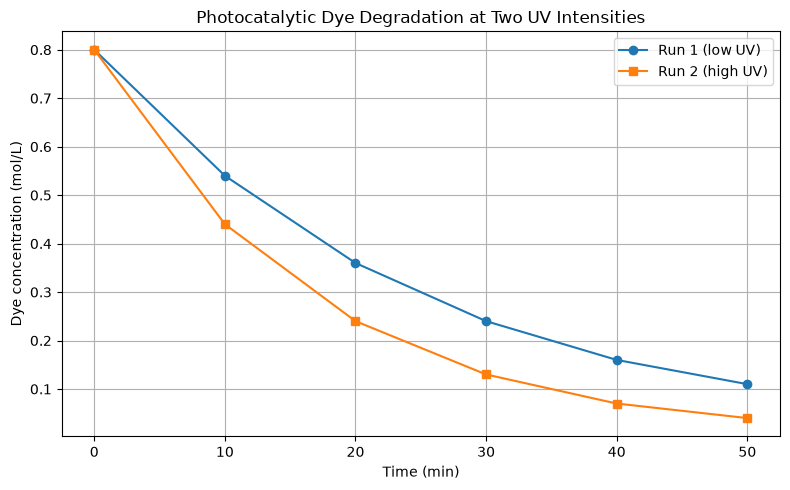


Mean P x V, k = 6.010 bar·L


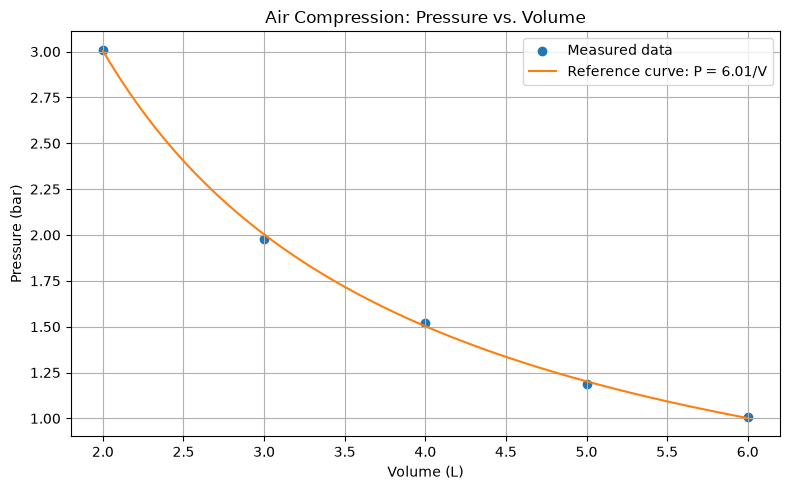

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: photocatalytic dye-degradation measurements.
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_UV": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_mol_L_high_UV": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04],
})

kinetics_df.to_csv("kinetic.csv", index=False)
kinetics_df.to_json("kinetic.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetic.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_df["Run1_mol_L_low_UV"].mean()
run1_std = kinetics_df["Run1_mol_L_low_UV"].std()
run2_mean = kinetics_df["Run2_mol_L_high_UV"].mean()
run2_std = kinetics_df["Run2_mol_L_high_UV"].std()
print(f"\nRun 1 (low UV): mean = {run1_mean:.4f} mol/L, sample standard deviation = {run1_std:.4f} mol/L")
print(f"Run 2 (high UV): mean = {run2_mean:.4f} mol/L, sample standard deviation = {run2_std:.4f} mol/L")
if run1_std > run2_std:
    print("Run 1 shows more variation (larger standard deviation).")
elif run2_std > run1_std:
    print("Run 2 shows more variation (larger standard deviation).")
else:
    print("Both runs show the same variation (equal standard deviations).")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_df["Time_min"], kinetics_df["Run1_mol_L_low_UV"], marker="o", label="Run 1 (low UV)")
plt.plot(kinetics_df["Time_min"], kinetics_df["Run2_mol_L_high_UV"], marker="s", label="Run 2 (high UV)")
plt.title("Photocatalytic Dye Degradation at Two UV Intensities")
plt.xlabel("Time (min)")
plt.ylabel("Dye concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part D: pressure-volume data and the mean-PV reference curve.
pv_df = pd.DataFrame({
    "Volume_L": [2, 3, 4, 5, 6],
    "Pressure_bar": [3.01, 1.98, 1.52, 1.19, 1.01],
})
pv_df["PV_bar_L"] = pv_df["Volume_L"] * pv_df["Pressure_bar"]
k = pv_df["PV_bar_L"].mean()
print(f"\nMean P x V, k = {k:.3f} bar·L")

volume_curve = np.linspace(pv_df["Volume_L"].min(), pv_df["Volume_L"].max(), 200)
pressure_curve = k / volume_curve
plt.figure(figsize=(8, 5))
plt.scatter(pv_df["Volume_L"], pv_df["Pressure_bar"], label="Measured data")
plt.plot(volume_curve, pressure_curve, color="tab:orange", label=f"Reference curve: P = {k:.2f}/V")
plt.title("Air Compression: Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
